In [ ]:
import torch
print('CUDA:', torch.cuda.is_available())
print('GPU:', torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'YOK')
print('PyTorch:', torch.__version__)

CUDA: True
GPU: Tesla T4
PyTorch: 2.11.0+cu128


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
!pip install timm --quiet

In [ ]:
import os

PROJECT_DIR = '/content/drive/MyDrive/bitirme_son3/sadece_onler/mixupli3'

# Dataset zip
ZIP_PATH = '/content/drive/MyDrive/bitirme_son3/all_last7.zip'

DATA_ROOT_DRIVE = None

OUTPUT_DIR = f'{PROJECT_DIR}/effnetb3_6class_benchmark_70_15_15_long'
CKPT_DIR   = f'{OUTPUT_DIR}/checkpoints'
os.makedirs(CKPT_DIR, exist_ok=True)

EXTRACT_DIR = '/content/data'
LOCAL_ZIP   = '/content/dataset.zip'

RESET_LOCAL_DATA = True

# Last 5 class
TARGET_CLASSES = [
    'flies_leaf',
    'healthy_leaf',
    'nutdef_leaf',
    'trips_leaf',
    'tuta_leaf'
]

# ORIGINAL TRAINING HYPERPARAMETERS
MODEL_NAME    = 'efficientnet_b3'
IMG_SIZE      = 300
BATCH_SIZE    = 48
EPOCHS        = 80
LR            = 1e-3
LR_BACKBONE   = 1e-4
WEIGHT_DECAY  = 1e-4
LABEL_SMOOTH  = 0.1
MIXUP_ALPHA   = 0.2
CUTMIX_ALPHA  = 1.0
MIX_PROB      = 0.5
EMA_DECAY     = 0.9998
PATIENCE      = 10
MIN_DELTA     = 1e-4
RESUME_FROM_LAST = False
SEED          = 42

print(f'Model: {MODEL_NAME} @ {IMG_SIZE}x{IMG_SIZE}, batch {BATCH_SIZE}, {EPOCHS} epoch')
print('Hedef sınıflar:')
for i, c in enumerate(TARGET_CLASSES):
    print(f'  {i}: {c}')


Model: efficientnet_b3 @ 300x300, batch 48, 80 epoch
Hedef sınıflar:
  0: flies_leaf
  1: healthy_leaf
  2: nutdef_leaf
  3: trips_leaf
  4: tuta_leaf


In [ ]:
import random, numpy as np, torch

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = False
    torch.backends.cudnn.benchmark = True

    try:
        torch.set_float32_matmul_precision("high")
    except Exception:
        pass

set_seed(SEED)

In [ ]:
import shutil, zipfile, os

if RESET_LOCAL_DATA and os.path.exists(EXTRACT_DIR):
    print(f'Eski local dataset siliniyor: {EXTRACT_DIR}')
    shutil.rmtree(EXTRACT_DIR)

os.makedirs(EXTRACT_DIR, exist_ok=True)

if DATA_ROOT_DRIVE is not None:
    dst = os.path.join(EXTRACT_DIR, os.path.basename(DATA_ROOT_DRIVE.rstrip('/')))
    print(f'Drive klasörü lokale kopyalanıyor:\n  {DATA_ROOT_DRIVE}\n  -> {dst}')
    shutil.copytree(DATA_ROOT_DRIVE, dst, dirs_exist_ok=True)
    print('Kopyalama tamamlandı.')
else:

    if not os.path.exists(ZIP_PATH):
        raise FileNotFoundError(
            f'ZIP_PATH bulunamadı:\n{ZIP_PATH}\n\n'
            'ZIP_PATH değişkenini kendi zip dosyanın Drive yoluna göre düzelt.'
        )

    if not os.path.exists(LOCAL_ZIP):
        print('Drive zip dosyası lokale kopyalanıyor...')
        shutil.copy(ZIP_PATH, LOCAL_ZIP)
        print('Zip kopyalandı.')
    else:
        print('Local zip zaten var: kopyalama atlandı.')

    print('Zip açılıyor...')
    with zipfile.ZipFile(LOCAL_ZIP, 'r') as f:
        f.extractall(EXTRACT_DIR)
    print('Zip açıldı.')

print('\n/content/data içeriği:')
print(sorted(os.listdir(EXTRACT_DIR))[:20])


Drive zip dosyası lokale kopyalanıyor...
Zip kopyalandı.
Zip açılıyor...
Zip açıldı.

/content/data içeriği:
['all_last']


In [ ]:
from sklearn.model_selection import train_test_split
from collections import Counter
import os

VALID_EXTS = ('.jpg', '.jpeg', '.png', '.bmp', '.webp')

TRAIN_RATIO = 0.70
VAL_RATIO   = 0.15
TEST_RATIO  = 0.15

assert abs(TRAIN_RATIO + VAL_RATIO + TEST_RATIO - 1.0) < 1e-9

def find_dataset_root(start_dir, target_classes):
    """
    start_dir altında, TARGET_CLASSES klasörlerinin hepsini aynı anda içeren
    klasörü bulur. Örnek:
      /content/data/all_last
      /content/data/train_images
      /content/data/dataset/train_images
    """
    target_set = set(target_classes)

    try:
        names = set(os.listdir(start_dir))
        if target_set.issubset(names):
            return start_dir
    except Exception:
        pass

    for root, dirs, files in os.walk(start_dir):
        dirs[:] = [d for d in dirs if not d.startswith('.') and d != '__MACOSX']
        if target_set.issubset(set(dirs)):
            return root

    raise FileNotFoundError(
        'TARGET_CLASSES klasörlerinin hepsini aynı kök altında bulamadım.\n'
        f'Aranan sınıflar: {target_classes}\n'
        f'Aranan konum: {start_dir}\n\n'
        'Zip yapını veya TARGET_CLASSES listesini kontrol et.'
    )

DATA_ROOT_LOCAL = find_dataset_root(EXTRACT_DIR, TARGET_CLASSES)
print(f'Dataset root bulundu: {DATA_ROOT_LOCAL}')

classes = TARGET_CLASSES.copy()
class_to_idx = {c: i for i, c in enumerate(classes)}
NUM_CLASSES = len(classes)
print(f'Sınıf sayısı: {NUM_CLASSES}')

all_samples = []
class_counts = {}

for c in classes:
    folder = os.path.join(DATA_ROOT_LOCAL, c)
    paths_c = []

    for root, dirs, files in os.walk(folder):
        dirs[:] = [d for d in dirs if not d.startswith('.') and d != '__MACOSX']
        for f in files:
            if f.lower().endswith(VALID_EXTS):
                paths_c.append(os.path.join(root, f))

    paths_c = sorted(paths_c)
    class_counts[c] = len(paths_c)

    for p in paths_c:
        all_samples.append((p, class_to_idx[c]))

print('\nSınıf örnek sayıları:')
for c in classes:
    print(f'  {c:<20}: {class_counts[c]}')

missing = [c for c, n in class_counts.items() if n == 0]
if missing:
    raise ValueError(f'Boş sınıf klasörü var: {missing}')

too_small = [c for c, n in class_counts.items() if n < 5]
if too_small:
    raise ValueError(
        f'Bu sınıflarda sağlıklı stratified train/val/test split için çok az örnek var: {too_small}'
    )

paths  = [s[0] for s in all_samples]
labels = [s[1] for s in all_samples]
print(f'\nToplam örnek: {len(paths)}')

trainval_paths, test_paths, trainval_labels, test_labels = train_test_split(
    paths, labels,
    test_size=TEST_RATIO,
    stratify=labels,
    random_state=SEED,
)

val_size_inside_trainval = VAL_RATIO / (TRAIN_RATIO + VAL_RATIO)
train_paths, val_paths, train_labels, val_labels = train_test_split(
    trainval_paths, trainval_labels,
    test_size=val_size_inside_trainval,
    stratify=trainval_labels,
    random_state=SEED,
)

print(f'Train: {len(train_paths)} | Val: {len(val_paths)} | Test: {len(test_paths)}')

print('\nTrain dağılımı:')
train_counts = Counter(train_labels)
for idx, c in enumerate(classes):
    print(f'  {c:<20}: {train_counts[idx]}')

print('\nVal dağılımı:')
val_counts = Counter(val_labels)
for idx, c in enumerate(classes):
    print(f'  {c:<20}: {val_counts[idx]}')

print('\nTest dağılımı:')
test_counts = Counter(test_labels)
for idx, c in enumerate(classes):
    print(f'  {c:<20}: {test_counts[idx]}')


Dataset root bulundu: /content/data/all_last
Sınıf sayısı: 5

Sınıf örnek sayıları:
  flies_leaf          : 1997
  healthy_leaf        : 4325
  nutdef_leaf         : 943
  trips_leaf          : 1991
  tuta_leaf           : 98

Toplam örnek: 9354
Train: 6547 | Val: 1403 | Test: 1404

Train dağılımı:
  flies_leaf          : 1398
  healthy_leaf        : 3027
  nutdef_leaf         : 661
  trips_leaf          : 1393
  tuta_leaf           : 68

Val dağılımı:
  flies_leaf          : 299
  healthy_leaf        : 649
  nutdef_leaf         : 141
  trips_leaf          : 299
  tuta_leaf           : 15

Test dağılımı:
  flies_leaf          : 300
  healthy_leaf        : 649
  nutdef_leaf         : 141
  trips_leaf          : 299
  tuta_leaf           : 15


In [ ]:
from torchvision import transforms

# ImageNet statistics
IM_MEAN = [0.485, 0.456, 0.406]
IM_STD  = [0.229, 0.224, 0.225]

train_tf = transforms.Compose([
    transforms.RandomResizedCrop(IMG_SIZE, scale=(0.7, 1.0)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.5),
    transforms.RandAugment(num_ops=2, magnitude=9),
    transforms.ToTensor(),
    transforms.Normalize(mean=IM_MEAN, std=IM_STD),
    transforms.RandomErasing(p=0.25, scale=(0.02, 0.15)),
])

val_tf = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=IM_MEAN, std=IM_STD),
])

In [ ]:
from torch.utils.data import Dataset
from PIL import Image

class LeafDataset(Dataset):
    def __init__(self, paths, labels, transform):
        self.paths = paths
        self.labels = labels
        self.transform = transform

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, idx):
        img = Image.open(self.paths[idx]).convert('RGB')
        img = self.transform(img)
        return img, self.labels[idx]

train_ds = LeafDataset(train_paths, train_labels, train_tf)
val_ds   = LeafDataset(val_paths,   val_labels,   val_tf)
test_ds  = LeafDataset(test_paths,  test_labels,  val_tf)
print(f'Train: {len(train_ds)} | Val: {len(val_ds)} | Test: {len(test_ds)}')

img, lbl = train_ds[0]
print(f'Örnek tensor: {img.shape}, dtype {img.dtype}, range [{img.min():.2f}, {img.max():.2f}]')
print(f'Etiket: {lbl} ({classes[lbl]})')

Train: 6547 | Val: 1403 | Test: 1404
Örnek tensor: torch.Size([3, 300, 300]), dtype torch.float32, range [-2.12, 2.64]
Etiket: 1 (healthy_leaf)


In [ ]:
from torch.utils.data import DataLoader, WeightedRandomSampler
import numpy as np
import torch

NUM_WORKERS = 4

# WEIGHTED TRAIN SAMPLER

train_labels_np = np.array(train_labels, dtype=np.int64)

class_counts = np.bincount(train_labels_np, minlength=NUM_CLASSES)
print("Train class counts:", class_counts)

class_sample_weights = 1.0 / np.maximum(class_counts, 1)
sample_weights = class_sample_weights[train_labels_np]

train_sampler = WeightedRandomSampler(
    weights=torch.as_tensor(sample_weights, dtype=torch.double),
    num_samples=len(sample_weights),
    replacement=True
)

print("train_sampler hazır.")

assert len(train_ds) == len(train_labels_np), "train_ds ile train_labels uzunluğu eşleşmiyor!"


# DATALOADERS

train_loader = DataLoader(
    train_ds,
    batch_size=BATCH_SIZE,
    sampler=train_sampler,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True,
    drop_last=True,
    persistent_workers=True,
    prefetch_factor=4,
)

val_loader = DataLoader(
    val_ds,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True,
    persistent_workers=True,
    prefetch_factor=4,
)

test_loader = DataLoader(
    test_ds,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True,
    persistent_workers=True,
    prefetch_factor=4,
)

print(f"Batch sayısı — train: {len(train_loader)}, val: {len(val_loader)}, test: {len(test_loader)}")

# Sanity check
imgs, lbls = next(iter(train_loader))
print(f"Batch örnek: imgs {imgs.shape}, labels {lbls.shape}")
print(f"Bir batch'te {len(set(lbls.tolist()))} farklı sınıf var (toplam {NUM_CLASSES})")

Train class counts: [1398 3027  661 1393   68]
train_sampler hazır.
Batch sayısı — train: 136, val: 30, test: 30


/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:424: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()
/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:432: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()


Batch örnek: imgs torch.Size([48, 3, 300, 300]), labels torch.Size([48])
Bir batch'te 5 farklı sınıf var (toplam 5)


In [ ]:
import timm

model = timm.create_model(
    MODEL_NAME,
    pretrained=True,
    num_classes=NUM_CLASSES,
)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model = model.to(device)

total_params     = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f'Model: {MODEL_NAME}')
print(f'Toplam parametre:   {total_params:,}')
print(f'Eğitilebilir:       {trainable_params:,}')
print(f'Cihaz: {device}')

# Sanity check
imgs, _ = next(iter(train_loader))
imgs = imgs.to(device)
with torch.no_grad():
    out = model(imgs)
print(f'\nGiriş: {imgs.shape}')
print(f'Çıkış: {out.shape}  (beklenen: [{BATCH_SIZE}, {NUM_CLASSES}])')

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:112: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


model.safetensors:   0%|          | 0.00/49.3M [00:00<?, ?B/s]

Model: efficientnet_b3
Toplam parametre:   10,703,917
Eğitilebilir:       10,703,917
Cihaz: cuda

Giriş: torch.Size([48, 3, 300, 300])
Çıkış: torch.Size([48, 5])  (beklenen: [48, 5])


In [ ]:
head_params, backbone_params = [], []
for name, p in model.named_parameters():
    if 'classifier' in name:   # head
        head_params.append(p)
    else:                       # backbone
        backbone_params.append(p)

print(f'Head param sayısı:     {sum(p.numel() for p in head_params):,}')
print(f'Backbone param sayısı: {sum(p.numel() for p in backbone_params):,}')

Head param sayısı:     7,685
Backbone param sayısı: 10,696,232


In [ ]:
# MixUp - CutMix

import numpy as np
import torch.nn.functional as F

def mixup_data(x, y, alpha):
    lam = np.random.beta(alpha, alpha) if alpha > 0 else 1.0
    idx = torch.randperm(x.size(0), device=x.device)
    mixed_x = lam * x + (1 - lam) * x[idx]
    return mixed_x, y, y[idx], lam

def cutmix_data(x, y, alpha):
    lam = np.random.beta(alpha, alpha) if alpha > 0 else 1.0
    idx = torch.randperm(x.size(0), device=x.device)
    B, C, H, W = x.size()

    cut_rat = np.sqrt(1.0 - lam)
    cut_w, cut_h = int(W * cut_rat), int(H * cut_rat)
    cx, cy = np.random.randint(W), np.random.randint(H)
    bbx1 = np.clip(cx - cut_w // 2, 0, W); bby1 = np.clip(cy - cut_h // 2, 0, H)
    bbx2 = np.clip(cx + cut_w // 2, 0, W); bby2 = np.clip(cy + cut_h // 2, 0, H)
    x_out = x.clone()
    x_out[:, :, bby1:bby2, bbx1:bbx2] = x[idx, :, bby1:bby2, bbx1:bbx2]

    lam = 1 - ((bbx2 - bbx1) * (bby2 - bby1) / (W * H))
    return x_out, y, y[idx], lam

def mix_criterion(criterion, pred, y_a, y_b, lam):
    return lam * criterion(pred, y_a) + (1 - lam) * criterion(pred, y_b)

In [ ]:
from copy import deepcopy

class ModelEMA:
    """Modelin exponential moving average kopyası."""
    def __init__(self, model, decay=0.9998):
        self.module = deepcopy(model).eval()
        self.decay = decay
        for p in self.module.parameters():
            p.requires_grad_(False)

    @torch.no_grad()
    def update(self, model):
        for ema_p, p in zip(self.module.parameters(), model.parameters()):
            ema_p.mul_(self.decay).add_(p.detach(), alpha=1 - self.decay)

        for ema_b, b in zip(self.module.buffers(), model.buffers()):
            ema_b.copy_(b)

ema = ModelEMA(model, decay=EMA_DECAY)
print('EMA initialized.')

EMA initialized.


In [ ]:
import torch.nn as nn
from torch.optim import AdamW
from torch.optim.lr_scheduler import CosineAnnealingLR
from torch.amp import autocast, GradScaler

criterion = nn.CrossEntropyLoss(label_smoothing=LABEL_SMOOTH)

# Discriminative LR
optimizer = AdamW([
    {'params': backbone_params, 'lr': LR_BACKBONE},
    {'params': head_params,     'lr': LR},
], weight_decay=WEIGHT_DECAY)

scheduler = CosineAnnealingLR(optimizer, T_max=EPOCHS)
scaler    = GradScaler('cuda')

print(f'Optimizer: AdamW (backbone LR {LR_BACKBONE}, head LR {LR})')
print(f'Scheduler: CosineAnnealing T_max={EPOCHS}')

Optimizer: AdamW (backbone LR 0.0001, head LR 0.001)
Scheduler: CosineAnnealing T_max=80


In [ ]:
def train_one_epoch(model, loader, criterion, optimizer, scaler, device, ema):
    model.train()
    total_loss, correct, total = 0.0, 0, 0
    for imgs, labels in loader:
        imgs   = imgs.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)
        optimizer.zero_grad()

        # MixUp / CutMix
        use_mix = np.random.rand() < MIX_PROB
        if use_mix:
            if np.random.rand() < 0.5:
                imgs, y_a, y_b, lam = mixup_data(imgs, labels, MIXUP_ALPHA)
            else:
                imgs, y_a, y_b, lam = cutmix_data(imgs, labels, CUTMIX_ALPHA)

        with autocast('cuda'):
            outputs = model(imgs)
            if use_mix:
                loss = mix_criterion(criterion, outputs, y_a, y_b, lam)
            else:
                loss = criterion(outputs, labels)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        ema.update(model)

        total_loss += loss.item() * imgs.size(0)

        preds = outputs.argmax(dim=1)
        correct += (preds == labels).sum().item()
        total   += imgs.size(0)

    return total_loss / total, correct / total

@torch.no_grad()
def evaluate(model, loader, criterion, device):
    model.eval()
    total_loss, correct, total = 0.0, 0, 0
    for imgs, labels in loader:
        imgs   = imgs.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)
        with autocast('cuda'):
            outputs = model(imgs)
            loss = criterion(outputs, labels)
        total_loss += loss.item() * imgs.size(0)
        preds = outputs.argmax(dim=1)
        correct += (preds == labels).sum().item()
        total   += imgs.size(0)
    return total_loss / total, correct / total

In [ ]:
# Training loop

import time

CKPT_BEST_EMA = f'{CKPT_DIR}/{MODEL_NAME}_best_ema.pt'
CKPT_BEST_RAW = f'{CKPT_DIR}/{MODEL_NAME}_best_raw.pt'
CKPT_LAST     = f'{CKPT_DIR}/{MODEL_NAME}_last_training_state.pt'
HIST_PATH     = f'{CKPT_DIR}/{MODEL_NAME}_history.pt'

history = {
    'train_loss': [], 'train_acc': [],
    'val_loss':   [], 'val_acc':   [],
    'val_loss_ema': [], 'val_acc_ema': [],
    'lr_backbone': [], 'lr_head': [],
}
best_val_acc_ema = 0.0
best_val_acc_raw = 0.0
no_improve = 0
start_epoch = 1

if RESUME_FROM_LAST and os.path.exists(CKPT_LAST):
    last = torch.load(CKPT_LAST, weights_only=False)
    model.load_state_dict(last['model_state_dict'])
    ema.module.load_state_dict(last['ema_state_dict'])
    optimizer.load_state_dict(last['optimizer_state_dict'])
    scheduler.load_state_dict(last['scheduler_state_dict'])
    scaler.load_state_dict(last['scaler_state_dict'])
    history = last['history']
    best_val_acc_ema = last['best_val_acc_ema']
    best_val_acc_raw = last['best_val_acc_raw']
    no_improve = last['no_improve']
    start_epoch = last['epoch'] + 1
    print(f'Last checkpoint yüklendi. Devam epoch: {start_epoch}/{EPOCHS}')

print(f'{"Epoch":>5} | {"TrLoss":>7} {"TrAcc":>7} | {"VlLoss":>7} {"VlAcc":>7} | {"EMA Loss":>8} {"EMA Acc":>8} | {"LRb":>8} {"LRh":>8} | {"Time":>6}')
print('-' * 110)

for epoch in range(start_epoch, EPOCHS + 1):
    t0 = time.time()

    train_loss, train_acc = train_one_epoch(model, train_loader, criterion, optimizer, scaler, device, ema)
    val_loss,   val_acc   = evaluate(model,        val_loader, criterion, device)
    ema_loss,   ema_acc   = evaluate(ema.module,   val_loader, criterion, device)

    lr_b = optimizer.param_groups[0]['lr']
    lr_h = optimizer.param_groups[1]['lr']
    scheduler.step()

    history['train_loss'].append(train_loss); history['train_acc'].append(train_acc)
    history['val_loss'].append(val_loss);     history['val_acc'].append(val_acc)
    history['val_loss_ema'].append(ema_loss); history['val_acc_ema'].append(ema_acc)
    history['lr_backbone'].append(lr_b);      history['lr_head'].append(lr_h)

    elapsed = time.time() - t0
    print(f'{epoch:>5} | {train_loss:>7.4f} {train_acc:>7.4f} | {val_loss:>7.4f} {val_acc:>7.4f} | {ema_loss:>8.4f} {ema_acc:>8.4f} | {lr_b:>8.2e} {lr_h:>8.2e} | {elapsed:>5.1f}s')

    improved = False
    if ema_acc > best_val_acc_ema + MIN_DELTA:
        best_val_acc_ema = ema_acc
        torch.save({
            'epoch': epoch,
            'model_state_dict': ema.module.state_dict(),
            'val_acc': ema_acc,
            'classes': classes,
            'img_size': IMG_SIZE,
            'model_name': MODEL_NAME,
            'split': {'train': TRAIN_RATIO, 'val': VAL_RATIO, 'test': TEST_RATIO},
        }, CKPT_BEST_EMA)
        improved = True
        print(f'      ↑ Yeni en iyi EMA val acc: {ema_acc:.4f} — kaydedildi')

    if val_acc > best_val_acc_raw + MIN_DELTA:
        best_val_acc_raw = val_acc
        torch.save({
            'epoch': epoch,
            'model_state_dict': model.state_dict(),
            'val_acc': val_acc,
            'classes': classes,
            'img_size': IMG_SIZE,
            'model_name': MODEL_NAME,
            'split': {'train': TRAIN_RATIO, 'val': VAL_RATIO, 'test': TEST_RATIO},
        }, CKPT_BEST_RAW)

    if improved:
        no_improve = 0
    else:
        no_improve += 1


    torch.save({
        'epoch': epoch,
        'model_state_dict': model.state_dict(),
        'ema_state_dict': ema.module.state_dict(),
        'optimizer_state_dict': optimizer.state_dict(),
        'scheduler_state_dict': scheduler.state_dict(),
        'scaler_state_dict': scaler.state_dict(),
        'history': history,
        'best_val_acc_ema': best_val_acc_ema,
        'best_val_acc_raw': best_val_acc_raw,
        'no_improve': no_improve,
        'classes': classes,
        'img_size': IMG_SIZE,
        'model_name': MODEL_NAME,
    }, CKPT_LAST)
    torch.save(history, HIST_PATH)

    if no_improve >= PATIENCE:
        print(f'\nEarly stopping — {PATIENCE} epoch boyunca EMA val acc iyileşmedi.')
        break

print(f'\nBitti. Best EMA val acc: {best_val_acc_ema:.4f} | Best raw val acc: {best_val_acc_raw:.4f}')


Epoch |  TrLoss   TrAcc |  VlLoss   VlAcc | EMA Loss  EMA Acc |      LRb      LRh |   Time
--------------------------------------------------------------------------------------------------------------


/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:432: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()


    1 |  1.5122  0.5205 |  0.9321  0.7349 |   2.4685   0.2053 | 1.00e-04 1.00e-03 | 216.9s
      ↑ Yeni en iyi EMA val acc: 0.2053 — kaydedildi
    2 |  0.9349  0.6907 |  0.7267  0.8603 |   1.6460   0.3999 | 1.00e-04 1.00e-03 | 140.7s
      ↑ Yeni en iyi EMA val acc: 0.3999 — kaydedildi
    3 |  0.8380  0.7376 |  0.6638  0.8959 |   1.5958   0.4669 | 9.98e-05 9.98e-04 | 149.8s
      ↑ Yeni en iyi EMA val acc: 0.4669 — kaydedildi
    4 |  0.8266  0.7345 |  0.6096  0.9237 |   1.5867   0.4775 | 9.97e-05 9.97e-04 | 152.6s
      ↑ Yeni en iyi EMA val acc: 0.4775 — kaydedildi
    5 |  0.7833  0.7293 |  0.5905  0.9266 |   1.6178   0.4804 | 9.94e-05 9.94e-04 | 152.2s
      ↑ Yeni en iyi EMA val acc: 0.4804 — kaydedildi
    6 |  0.7480  0.7736 |  0.5723  0.9359 |   1.6246   0.4761 | 9.90e-05 9.90e-04 | 152.2s
    7 |  0.7692  0.7587 |  0.5643  0.9380 |   1.5806   0.4818 | 9.86e-05 9.86e-04 | 149.3s
      ↑ Yeni en iyi EMA val acc: 0.4818 — kaydedildi
    8 |  0.7229  0.8076 |  0.5444  0.9408 |  

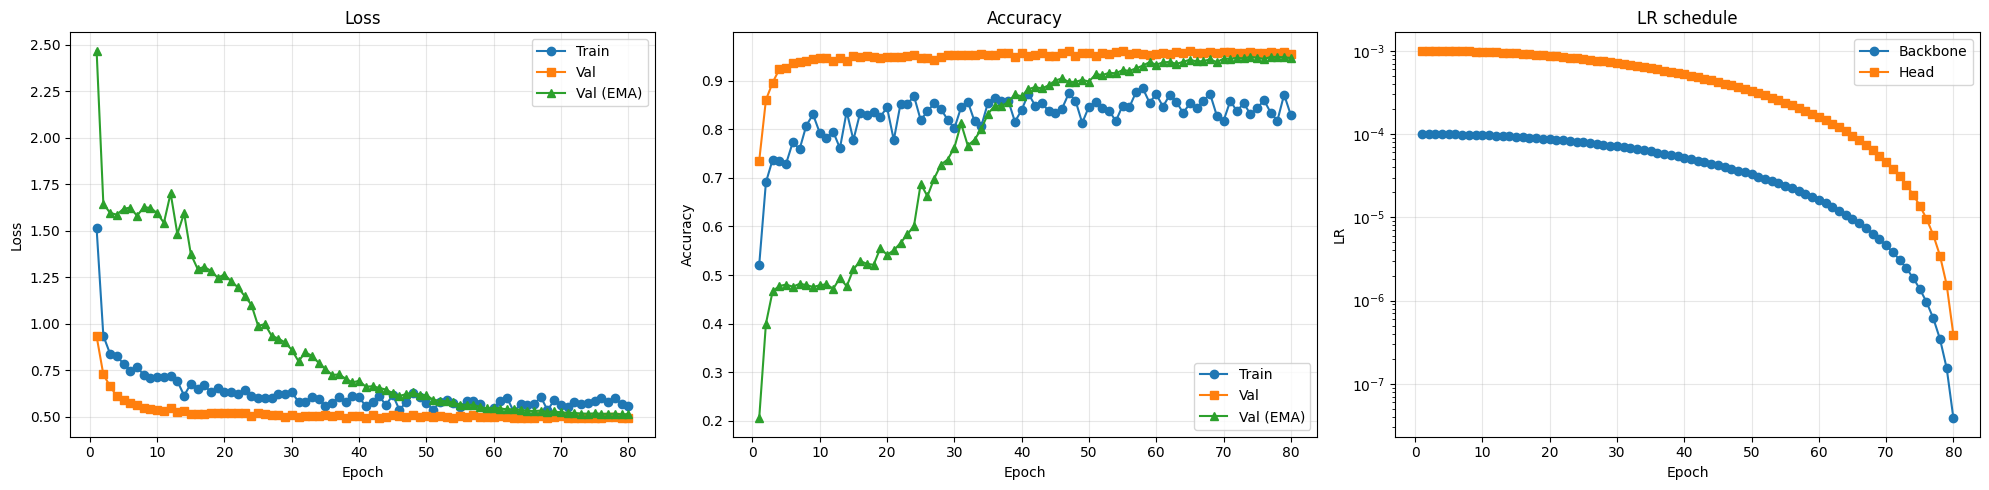

Final EMA val acc: 0.9465
Best  EMA val acc: 0.9487 (epoch 74)


In [ ]:
import matplotlib.pyplot as plt

hist = torch.load(HIST_PATH, weights_only=False)
n = len(hist['train_loss'])
epochs_range = range(1, n + 1)

fig, axes = plt.subplots(1, 3, figsize=(20, 5))

axes[0].plot(epochs_range, hist['train_loss'], label='Train', marker='o')
axes[0].plot(epochs_range, hist['val_loss'],   label='Val',   marker='s')
axes[0].plot(epochs_range, hist['val_loss_ema'], label='Val (EMA)', marker='^')
axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('Loss'); axes[0].set_title('Loss')
axes[0].legend(); axes[0].grid(True, alpha=0.3)

axes[1].plot(epochs_range, hist['train_acc'],     label='Train', marker='o')
axes[1].plot(epochs_range, hist['val_acc'],       label='Val',   marker='s')
axes[1].plot(epochs_range, hist['val_acc_ema'],   label='Val (EMA)', marker='^')
axes[1].set_xlabel('Epoch'); axes[1].set_ylabel('Accuracy'); axes[1].set_title('Accuracy')
axes[1].legend(); axes[1].grid(True, alpha=0.3)

axes[2].plot(epochs_range, hist['lr_backbone'], label='Backbone', marker='o')
axes[2].plot(epochs_range, hist['lr_head'],     label='Head',     marker='s')
axes[2].set_xlabel('Epoch'); axes[2].set_ylabel('LR'); axes[2].set_title('LR schedule')
axes[2].set_yscale('log'); axes[2].legend(); axes[2].grid(True, alpha=0.3)

plt.tight_layout(); plt.show()

print(f'Final EMA val acc: {hist["val_acc_ema"][-1]:.4f}')
print(f'Best  EMA val acc: {max(hist["val_acc_ema"]):.4f} (epoch {hist["val_acc_ema"].index(max(hist["val_acc_ema"]))+1})')

In [ ]:
# Last epoch check
hist = torch.load(HIST_PATH, weights_only=False)
ema_vals = hist['val_acc_ema']
raw_vals = hist['val_acc']

last_n = min(5, len(ema_vals))
best_epoch = int(np.argmax(ema_vals)) + 1
best_ema = max(ema_vals)
last_ema = ema_vals[-1]

print(f'Toplam koşan epoch: {len(ema_vals)}')
print(f'Best EMA val acc  : {best_ema:.4f} | epoch {best_epoch}')
print(f'Son EMA val acc   : {last_ema:.4f}')
print(f'Son {last_n} EMA  : {[round(x, 4) for x in ema_vals[-last_n:]]}')

if best_epoch >= len(ema_vals) - 2:
    print('\nYorum: En iyi epoch sonlara çok yakın. Eğitim hâlâ gelişiyor olabilir; daha uzun koşmak mantıklı.')
elif len(ema_vals) - best_epoch >= PATIENCE:
    print('\nYorum: Uzun süredir iyileşme yok. Daha fazla epoch muhtemelen az katkı sağlar.')
else:
    print('\nYorum: Gelişme yavaşlamış olabilir ama tamamen bitmiş görünmüyor. Patience ile takip etmek en sağlıklısı.')


Toplam koşan epoch: 80
Best EMA val acc  : 0.9487 | epoch 74
Son EMA val acc   : 0.9465
Son 5 EMA  : [0.9444, 0.9487, 0.9487, 0.948, 0.9465]

Yorum: Gelişme yavaşlamış olabilir ama tamamen bitmiş görünmüyor. Patience ile takip etmek en sağlıklısı.


In [ ]:
import timm

# Best EMA model upload
ckpt = torch.load(CKPT_BEST_EMA, weights_only=False)
eval_model = timm.create_model(MODEL_NAME, pretrained=False, num_classes=NUM_CLASSES).to(device)
eval_model.load_state_dict(ckpt['model_state_dict'])
eval_model.eval()
print(f'Yüklendi — epoch {ckpt["epoch"]}, val_acc {ckpt["val_acc"]:.4f}')

all_preds, all_labels = [], []
with torch.no_grad():
    for imgs, labels in val_loader:
        imgs = imgs.to(device, non_blocking=True)
        with autocast('cuda'):
            outputs = eval_model(imgs)
        preds = outputs.argmax(dim=1).cpu()
        all_preds.append(preds); all_labels.append(labels)

all_preds  = torch.cat(all_preds).numpy()
all_labels = torch.cat(all_labels).numpy()
print(f'Toplam tahmin: {len(all_preds)}')
print(f'Genel accuracy: {(all_preds == all_labels).mean():.4f}')

Yüklendi — epoch 74, val_acc 0.9487
Toplam tahmin: 1403
Genel accuracy: 0.9487


FINAL TEST ACCURACY: 0.9672  (96.72%)
              precision    recall  f1-score   support

  flies_leaf     0.9472    0.9567    0.9519       300
healthy_leaf     0.9769    0.9753    0.9761       649
 nutdef_leaf     0.9583    0.9787    0.9684       141
  trips_leaf     0.9696    0.9599    0.9647       299
   tuta_leaf     1.0000    0.8667    0.9286        15

    accuracy                         0.9672      1404
   macro avg     0.9704    0.9475    0.9579      1404
weighted avg     0.9674    0.9672    0.9672      1404



,file_path,true_idx,true_class,pred_idx,pred_class,confidence,correct,prob_flies_leaf,prob_healthy_leaf,prob_nutdef_leaf,prob_trips_leaf,prob_tuta_leaf
0,/content/data/all_last/flies_leaf/extra_w10_la...,0,flies_leaf,0,flies_leaf,0.597168,True,0.597168,0.124817,0.123169,0.093323,0.061493
1,/content/data/all_last/healthy_leaf/yolo_w1_la...,1,healthy_leaf,1,healthy_leaf,0.939941,True,0.007889,0.939941,0.007751,0.032654,0.011833
2,/content/data/all_last/healthy_leaf/yolo_w1_la...,1,healthy_leaf,1,healthy_leaf,0.973145,True,0.004776,0.973145,0.005154,0.005600,0.011185
3,/content/data/all_last/trips_leaf/trips_leaf__...,3,trips_leaf,3,trips_leaf,0.864258,True,0.017746,0.072266,0.029053,0.864258,0.016479
4,/content/data/all_last/healthy_leaf/yolo_w5_la...,1,healthy_leaf,1,healthy_leaf,0.937988,True,0.010201,0.937988,0.023575,0.014565,0.013580
5,/content/data/all_last/healthy_leaf/yolo_w4_la...,1,healthy_leaf,1,healthy_leaf,0.945312,True,0.004963,0.945312,0.019714,0.017532,0.012344
6,/content/data/all_last/nutdef_leaf/yolo_w6_las...,2,nutdef_leaf,2,nutdef_leaf,0.858398,True,0.031616,0.038055,0.858398,0.031555,0.040466
7,/content/data/all_last/healthy_leaf/yolo_ceren...,1,healthy_leaf,1,healthy_leaf,0.954590,True,0.007660,0.954590,0.012764,0.015656,0.009178
8,/content/data/all_last/healthy_leaf/yolo_w2_la...,1,healthy_leaf,1,healthy_leaf,0.862305,True,0.053192,0.862305,0.030487,0.035980,0.017975
9,/content/data/all_last/nutdef_leaf/yolo_w1_las...,2,nutdef_leaf,2,nutdef_leaf,0.892090,True,0.024887,0.034241,0.892090,0.032074,0.016830


<Figure size 900x900 with 0 Axes>

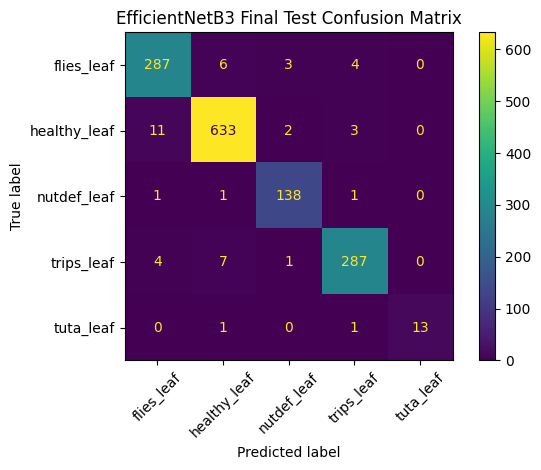

Kaydedilen çıktılar:
  Report TXT : /content/drive/MyDrive/bitirme_son3/sadece_onler/mixupli3/effnetb3_6class_benchmark_70_15_15_long/final_test_classification_report.txt
  Report JSON: /content/drive/MyDrive/bitirme_son3/sadece_onler/mixupli3/effnetb3_6class_benchmark_70_15_15_long/final_test_classification_report.json
  Predictions: /content/drive/MyDrive/bitirme_son3/sadece_onler/mixupli3/effnetb3_6class_benchmark_70_15_15_long/final_test_predictions.csv
  Confusion  : /content/drive/MyDrive/bitirme_son3/sadece_onler/mixupli3/effnetb3_6class_benchmark_70_15_15_long/final_test_confusion_matrix.png


In [ ]:
# Final test evaluation

from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
import pandas as pd
import json

@torch.no_grad()
def predict_loader(model, loader, device):
    model.eval()
    all_probs, all_preds, all_labels = [], [], []
    for imgs, labels in loader:
        imgs = imgs.to(device, non_blocking=True)
        with autocast('cuda'):
            logits = model(imgs)
        probs = F.softmax(logits, dim=1).cpu()
        preds = probs.argmax(dim=1)
        all_probs.append(probs)
        all_preds.append(preds)
        all_labels.append(labels.cpu())
    return (
        torch.cat(all_probs).numpy(),
        torch.cat(all_preds).numpy(),
        torch.cat(all_labels).numpy(),
    )

test_probs, test_preds, test_labels_arr = predict_loader(eval_model, test_loader, device)
test_acc = (test_preds == test_labels_arr).mean()
print(f'FINAL TEST ACCURACY: {test_acc:.4f}  ({test_acc*100:.2f}%)')

report_text = classification_report(
    test_labels_arr,
    test_preds,
    target_names=classes,
    digits=4,
)
print(report_text)

report_dict = classification_report(
    test_labels_arr,
    test_preds,
    target_names=classes,
    digits=4,
    output_dict=True,
)

final_report_txt = f'{OUTPUT_DIR}/final_test_classification_report.txt'
final_report_json = f'{OUTPUT_DIR}/final_test_classification_report.json'
final_preds_csv = f'{OUTPUT_DIR}/final_test_predictions.csv'
final_cm_png = f'{OUTPUT_DIR}/final_test_confusion_matrix.png'

with open(final_report_txt, 'w', encoding='utf-8') as f:
    f.write(report_text)

with open(final_report_json, 'w', encoding='utf-8') as f:
    json.dump(report_dict, f, indent=4, ensure_ascii=False)

rows = []
for i, (p, t) in enumerate(zip(test_preds, test_labels_arr)):
    row = {
        'file_path': test_paths[i],
        'true_idx': int(t),
        'true_class': classes[int(t)],
        'pred_idx': int(p),
        'pred_class': classes[int(p)],
        'confidence': float(test_probs[i, p]),
        'correct': bool(p == t),
    }
    for j, c in enumerate(classes):
        row[f'prob_{c}'] = float(test_probs[i, j])
    rows.append(row)

preds_df = pd.DataFrame(rows)
preds_df.to_csv(final_preds_csv, index=False)

display(preds_df.head(20))

cm_test = confusion_matrix(test_labels_arr, test_preds)
plt.figure(figsize=(9, 9))
disp = ConfusionMatrixDisplay(confusion_matrix=cm_test, display_labels=classes)
disp.plot(xticks_rotation=45, values_format='d')
plt.title('EfficientNetB3 Final Test Confusion Matrix')
plt.tight_layout()
plt.savefig(final_cm_png, dpi=220, bbox_inches='tight')
plt.show()

print('Kaydedilen çıktılar:')
print('  Report TXT :', final_report_txt)
print('  Report JSON:', final_report_json)
print('  Predictions:', final_preds_csv)
print('  Confusion  :', final_cm_png)


In [ ]:
import numpy as np

per_class_acc, per_class_count = {}, {}
for cls_idx in range(NUM_CLASSES):
    mask = all_labels == cls_idx
    if mask.sum() > 0:
        per_class_acc[classes[cls_idx]]   = (all_preds[mask] == cls_idx).mean()
        per_class_count[classes[cls_idx]] = int(mask.sum())

sorted_acc = sorted(per_class_acc.items(), key=lambda x: x[1])

print('=== SINIF BAZLI VALIDATION ACCURACY ===')
print(f'{"Sınıf":<25} {"Acc":>8} {"Val#":>6}')
print('-' * 45)
for c, a in sorted_acc:
    print(f'{c:<25} {a:>8.4f} {per_class_count[c]:>6}')

accs = list(per_class_acc.values())
print(f'\nOrtalama per-class acc: {np.mean(accs):.4f}')
print(f'Std: {np.std(accs):.4f}')
print(f'%80 altındaki sınıf sayısı: {sum(1 for a in accs if a < 0.80)}')
print(f'%90 altındaki sınıf sayısı: {sum(1 for a in accs if a < 0.90)}')


=== SINIF BAZLI VALIDATION ACCURACY ===
Sınıf                          Acc   Val#
---------------------------------------------
flies_leaf                  0.8863    299
tuta_leaf                   0.9333     15
trips_leaf                  0.9365    299
nutdef_leaf                 0.9433    141
healthy_leaf                0.9846    649

Ortalama per-class acc: 0.9368
Std: 0.0313
%80 altındaki sınıf sayısı: 0
%90 altındaki sınıf sayısı: 1


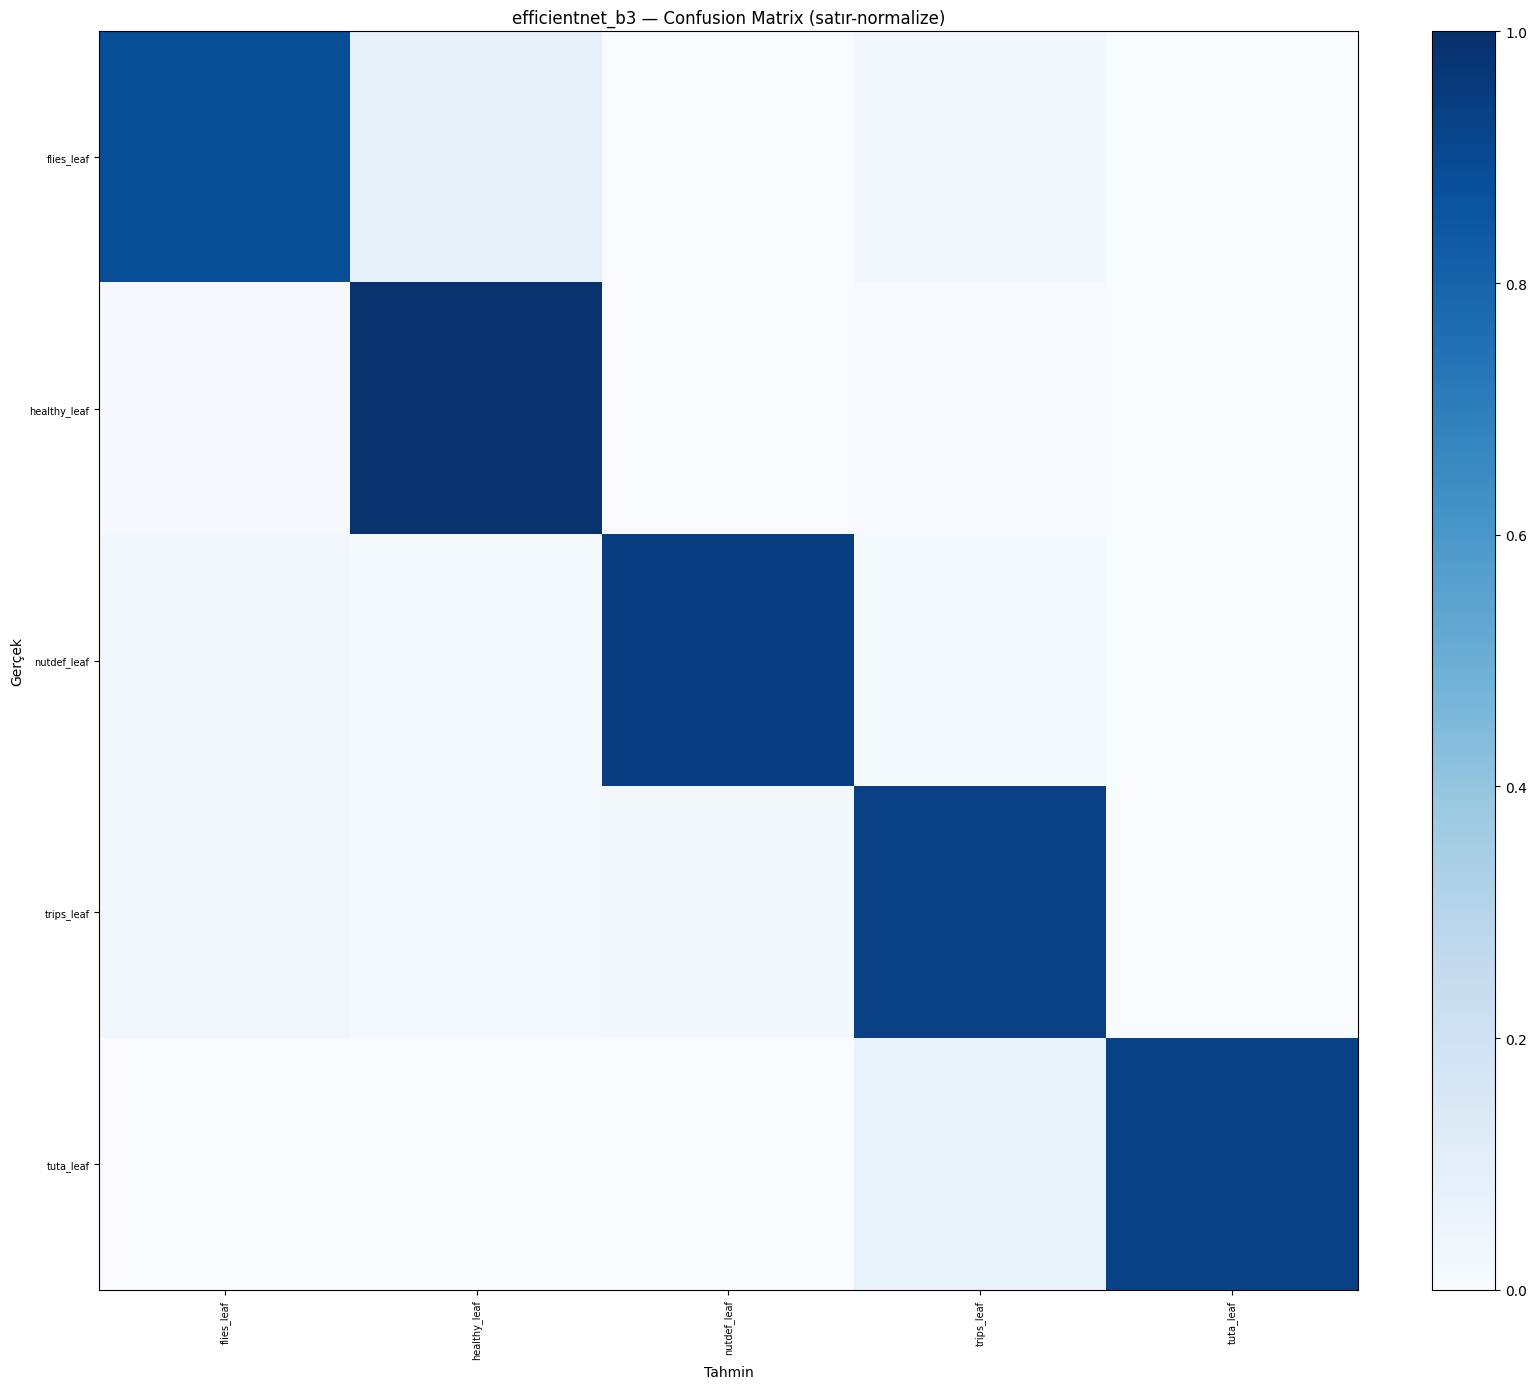


=== EN BASKIN 10 KARIŞTIRMA ===
Gerçek                                        → Tahmin                                         Sayı    Oran
--------------------------------------------------------------------------------------------------------------
flies_leaf                                    → healthy_leaf                                     25  8.36%
trips_leaf                                    → flies_leaf                                       10  3.34%
flies_leaf                                    → trips_leaf                                        9  3.01%
healthy_leaf                                  → flies_leaf                                        6  0.92%
trips_leaf                                    → nutdef_leaf                                       5  1.67%
nutdef_leaf                                   → flies_leaf                                        4  2.84%
trips_leaf                                    → healthy_leaf                                      4  1.34%

In [ ]:
# Confusion Matrix

from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt

cm = confusion_matrix(all_labels, all_preds, labels=range(NUM_CLASSES))
cm_norm = cm.astype(float) / cm.sum(axis=1, keepdims=True)

fig, ax = plt.subplots(figsize=(16, 14))
im = ax.imshow(cm_norm, cmap='Blues', vmin=0, vmax=1)
ax.set_xticks(range(NUM_CLASSES)); ax.set_yticks(range(NUM_CLASSES))
ax.set_xticklabels(classes, rotation=90, fontsize=7)
ax.set_yticklabels(classes, fontsize=7)
ax.set_xlabel('Tahmin'); ax.set_ylabel('Gerçek')
ax.set_title(f'{MODEL_NAME} — Confusion Matrix (satır-normalize)')
plt.colorbar(im, ax=ax, fraction=0.046)
plt.tight_layout(); plt.show()

print('\n=== EN BASKIN 10 KARIŞTIRMA ===')
print(f'{"Gerçek":<45} → {"Tahmin":<45} {"Sayı":>5} {"Oran":>7}')
print('-' * 110)
errors = []
for i in range(NUM_CLASSES):
    for j in range(NUM_CLASSES):
        if i != j and cm[i, j] > 0:
            errors.append((i, j, cm[i, j], cm_norm[i, j]))
errors.sort(key=lambda x: x[2], reverse=True)
for true_idx, pred_idx, count, ratio in errors[:10]:
    print(f'{classes[true_idx]:<45} → {classes[pred_idx]:<45} {count:>5} {ratio:>6.2%}')